# Week 1 — Collect and understand the estimation data
**Project:** Project Estimation Engine  
**Intern:** Armish Shaikh

This notebook explores two public software-effort datasets: COCOMO-81 and Desharnais. The goal is to understand dataset size, effort, project-size/productivity measures, missing values, and potential outliers before building models.

> Important: COCOMO-81 effort is in person-months, while Desharnais effort is in person-hours. The two targets are not directly comparable and are analyzed separately.

In [29]:
from pathlib import Path
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
RAW.mkdir(parents=True, exist_ok=True)

sources = {
    "cocomo81": "https://raw.githubusercontent.com/Derek-Jones/Software-estimation-datasets/main/COCOMO-81.csv",
    "desharnais": "https://raw.githubusercontent.com/Derek-Jones/Software-estimation-datasets/main/Desharnais.csv",
}
for name, url in sources.items():
    destination = RAW / f"{name}.csv"
    if not destination.exists():
        print(f"Downloading {name}...")
        urllib.request.urlretrieve(url, destination)
    else:
        print(f"Using existing file: {destination}")

cocomo_raw = pd.read_csv(RAW / "cocomo81.csv")
desharnais_raw = pd.read_csv(RAW / "desharnais.csv")

# Preserve the source data and work on copies for analysis.
cocomo = cocomo_raw.copy()
desharnais = desharnais_raw.copy()
# The Desharnais source uses -1 as a sentinel in experience fields.
for col in ["TeamExp", "ManagerExp"]:
    desharnais[col] = desharnais[col].replace(-1, np.nan)

print("COCOMO-81 shape:", cocomo.shape)
print("Desharnais shape:", desharnais.shape)
display(cocomo.head())
display(desharnais.head())

Using existing file: c:\Users\Dell 5400\Downloads\Armish_Week1_Project_Estimation (2)\data\raw\cocomo81.csv
Using existing file: c:\Users\Dell 5400\Downloads\Armish_Week1_Project_Estimation (2)\data\raw\desharnais.csv
COCOMO-81 shape: (63, 19)
Desharnais shape: (81, 13)


,num,dev_mode,rely,data,cplx,time,stor,virt,turn,acap,aexp,pcap,vexp,lexp,modp,tool,sced,loc,actual
0,1,embedded,0.88,1.16,0.70,1.0,1.06,1.15,1.07,1.19,1.13,1.17,1.1,1.00,1.24,1.10,1.04,113.0,2040.0
1,2,embedded,0.88,1.16,0.85,1.0,1.06,1.00,1.07,1.00,0.91,1.00,0.9,0.95,1.10,1.00,1.00,293.0,1600.0
2,3,semidetached,1.00,1.16,0.85,1.0,1.00,0.87,0.94,0.86,0.82,0.86,0.9,0.95,0.91,0.91,1.00,132.0,243.0
3,4,organic,0.75,1.16,0.70,1.0,1.00,0.87,1.00,1.19,0.91,1.42,1.0,0.95,1.24,1.00,1.04,60.0,240.0
4,5,organic,0.88,0.94,1.00,1.0,1.00,0.87,1.00,1.00,1.00,0.86,0.9,0.95,1.24,1.00,1.00,16.0,33.0


,id,Project,TeamExp,ManagerExp,YearEnd,Length,Effort,Transactions,Entities,PointsNonAdjust,Adjustment,PointsAjust,Language
0,1,1,1.0,4.0,85,12,5152,253,52,305,34,302,1
1,2,2,0.0,0.0,86,4,5635,197,124,321,33,315,1
2,3,3,4.0,4.0,85,1,805,40,60,100,18,83,1
3,4,4,0.0,0.0,86,5,3829,200,119,319,30,303,1
4,5,5,0.0,0.0,86,4,2149,140,94,234,24,208,1


## 1. Dataset structure and data types
The first check confirms the number of records, columns, and data types. This helps distinguish numeric project measures from categorical fields.

In [30]:
print("COCOMO-81")
display(cocomo.info())
print("\nDesharnais")
display(desharnais.info())

COCOMO-81
<class 'pandas.DataFrame'>
RangeIndex: 63 entries, 0 to 62
Data columns (total 19 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   num       63 non-null     int64  
 1   dev_mode  63 non-null     str    
 2   rely      63 non-null     float64
 3   data      63 non-null     float64
 4   cplx      63 non-null     float64
 5   time      63 non-null     float64
 6   stor      63 non-null     float64
 7   virt      63 non-null     float64
 8   turn      63 non-null     float64
 9   acap      63 non-null     float64
 10  aexp      63 non-null     float64
 11  pcap      63 non-null     float64
 12  vexp      63 non-null     float64
 13  lexp      63 non-null     float64
 14  modp      63 non-null     float64
 15  tool      63 non-null     float64
 16  sced      63 non-null     float64
 17  loc       63 non-null     float64
 18  actual    63 non-null     float64
dtypes: float64(17), int64(1), str(1)
memory usage: 9.5 KB


None


Desharnais
<class 'pandas.DataFrame'>
RangeIndex: 81 entries, 0 to 80
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               81 non-null     int64  
 1   Project          81 non-null     int64  
 2   TeamExp          79 non-null     float64
 3   ManagerExp       78 non-null     float64
 4   YearEnd          81 non-null     int64  
 5   Length           81 non-null     int64  
 6   Effort           81 non-null     int64  
 7   Transactions     81 non-null     int64  
 8   Entities         81 non-null     int64  
 9   PointsNonAdjust  81 non-null     int64  
 10  Adjustment       81 non-null     int64  
 11  PointsAjust      81 non-null     int64  
 12  Language         81 non-null     int64  
dtypes: float64(2), int64(11)
memory usage: 8.4 KB


None

## 2. Descriptive statistics for effort
Effort is the outcome we eventually want to estimate. These summaries show its range and spread in each dataset. Remember that the units differ.

In [31]:
display(cocomo["actual"].describe().to_frame("COCOMO81 effort (person-months)"))
display(desharnais["Effort"].describe().to_frame("Desharnais effort (person-hours)"))

,COCOMO81 effort (person-months)
count,63.000000
mean,683.526984
std,1821.511334
min,5.900000
25%,40.500000
50%,98.000000
75%,438.000000
max,11400.000000


,Desharnais effort (person-hours)
count,81.000000
mean,5046.308642
std,4418.767228
min,546.000000
25%,2352.000000
50%,3647.000000
75%,5922.000000
max,23940.000000


## 3. Data-quality checks: missing values and duplicates
Missing values and duplicate rows can affect analysis. The Desharnais sentinel values are converted to missing only in the analysis copy; the downloaded raw file remains unchanged.

In [32]:
quality = pd.DataFrame({
    "COCOMO81_missing": cocomo.isna().sum(),
    "Desharnais_missing": desharnais.isna().sum()
}).fillna(0).astype(int)
display(quality)
print("COCOMO-81 duplicate rows:", cocomo.duplicated().sum())
print("Desharnais duplicate rows:", desharnais.duplicated().sum())
print("Desharnais experience sentinels converted to NaN in analysis copy.")

,COCOMO81_missing,Desharnais_missing
Adjustment,0,0
Effort,0,0
Entities,0,0
Language,0,0
Length,0,0
ManagerExp,0,3
PointsAjust,0,0
PointsNonAdjust,0,0
Project,0,0
TeamExp,0,2


COCOMO-81 duplicate rows: 0
Desharnais duplicate rows: 0
Desharnais experience sentinels converted to NaN in analysis copy.


## 4. Plot 1 — Effort distributions
**Takeaway:** The histograms show whether effort values cluster at the lower end and whether a long right tail is present.

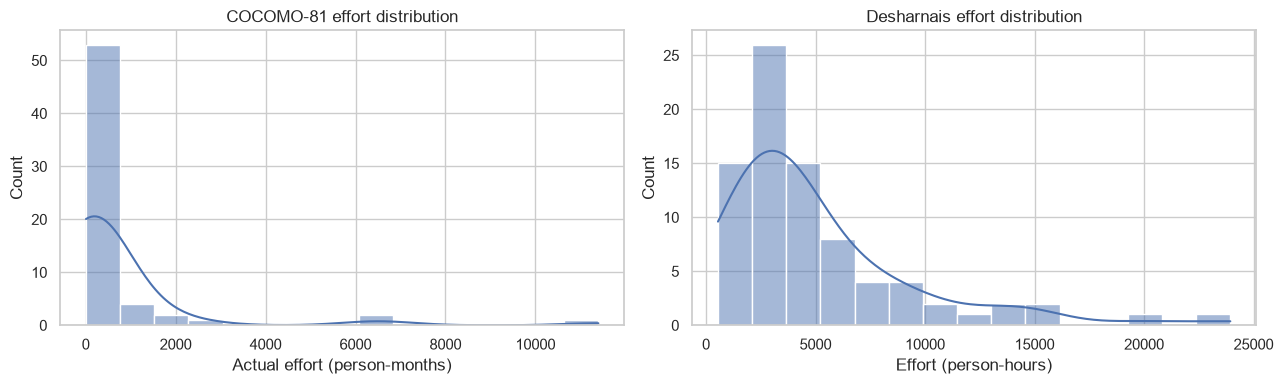

Takeaway: Compare the skew and spread within each dataset only; effort units are different.


In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(cocomo["actual"], bins=15, kde=True, ax=axes[0])
axes[0].set_title("COCOMO-81 effort distribution")
axes[0].set_xlabel("Actual effort (person-months)")
sns.histplot(desharnais["Effort"], bins=15, kde=True, ax=axes[1])
axes[1].set_title("Desharnais effort distribution")
axes[1].set_xlabel("Effort (person-hours)")
plt.tight_layout()
plt.show()
print("Takeaway: Compare the skew and spread within each dataset only; effort units are different.")

## 5. Plot 2 — Project size versus effort (COCOMO-81)
`loc` is the size field supplied in COCOMO-81. The scatter plot helps inspect whether larger projects tend to require more effort.

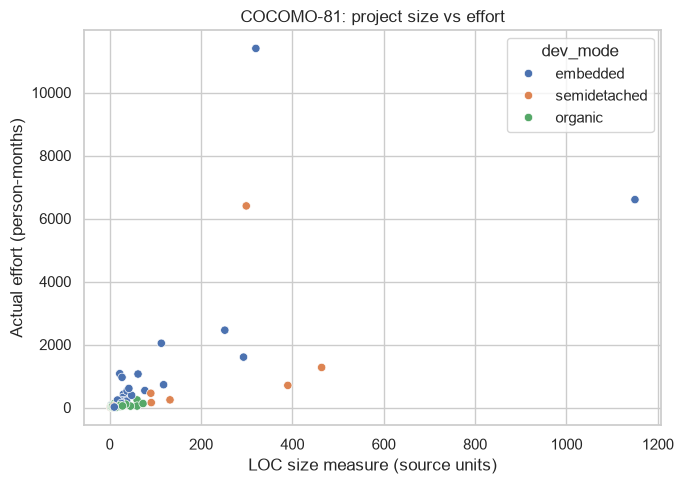

Takeaway: The plot can reveal a positive size-effort pattern, while also showing variation across development modes.


In [34]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=cocomo, x="loc", y="actual", hue="dev_mode")
plt.title("COCOMO-81: project size vs effort")
plt.xlabel("LOC size measure (source units)")
plt.ylabel("Actual effort (person-months)")
plt.tight_layout()
plt.show()
print("Takeaway: The plot can reveal a positive size-effort pattern, while also showing variation across development modes.")

## 6. Plot 3 — Effort by development mode (COCOMO-81)
This boxplot compares effort distributions for organic, semidetached, and embedded projects.

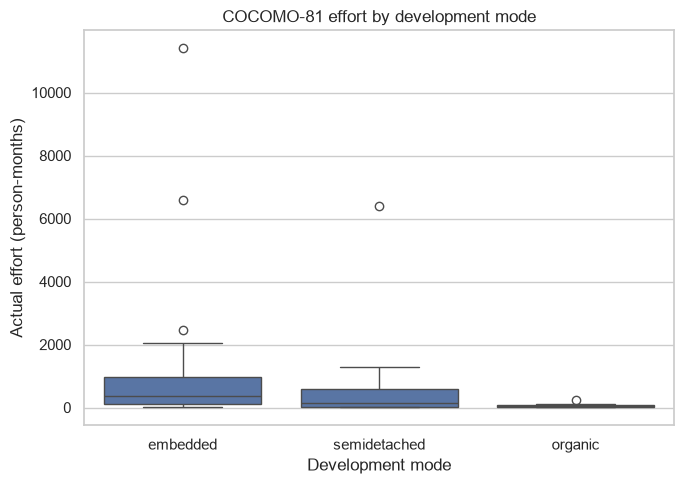

Takeaway: Differences in medians and spread suggest development mode may be associated with effort.


In [35]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=cocomo, x="dev_mode", y="actual")
plt.title("COCOMO-81 effort by development mode")
plt.xlabel("Development mode")
plt.ylabel("Actual effort (person-months)")
plt.tight_layout()
plt.show()
print("Takeaway: Differences in medians and spread suggest development mode may be associated with effort.")

## 7. Plot 4 — Size versus effort (Desharnais)
The Desharnais dataset contains function-point-related measures. Here adjusted function points are compared with actual effort.

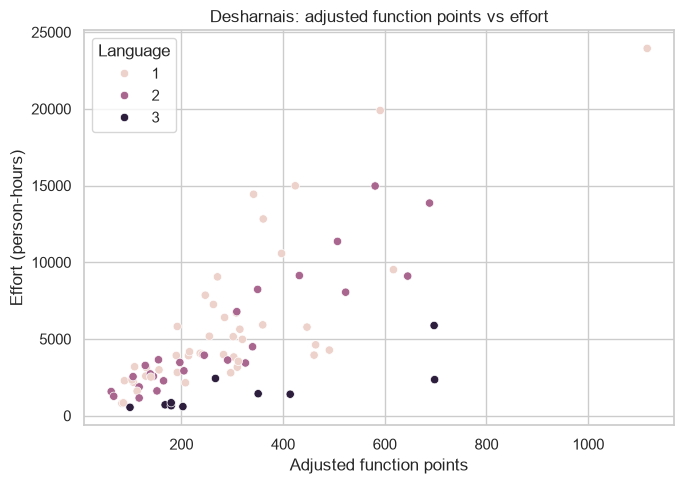

Takeaway: Check whether projects with more adjusted function points generally require more person-hours.


In [36]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=desharnais, x="PointsAjust", y="Effort", hue="Language")
plt.title("Desharnais: adjusted function points vs effort")
plt.xlabel("Adjusted function points")
plt.ylabel("Effort (person-hours)")
plt.tight_layout()
plt.show()
print("Takeaway: Check whether projects with more adjusted function points generally require more person-hours.")

## 8. Plot 5 — Effort by language category (Desharnais)
Language is stored as a category code. This plot compares the effort distributions without assuming that the codes have numeric order.

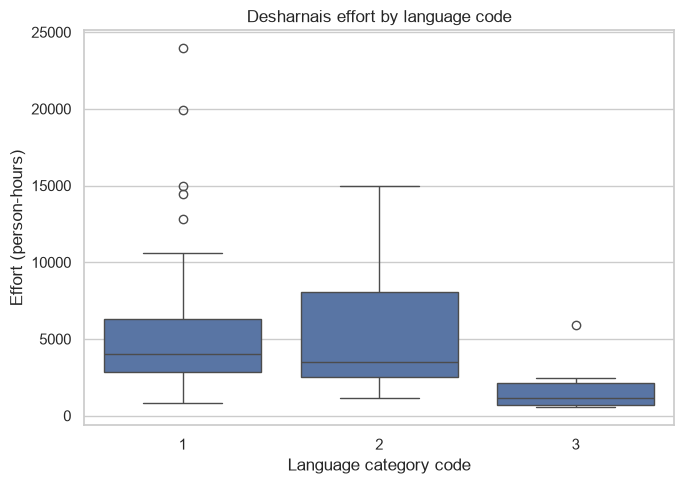

Takeaway: Differences between category distributions may be worth exploring, but the language codes are categorical.


In [37]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=desharnais, x=desharnais["Language"].astype(str), y="Effort")
plt.title("Desharnais effort by language code")
plt.xlabel("Language category code")
plt.ylabel("Effort (person-hours)")
plt.tight_layout()
plt.show()
print("Takeaway: Differences between category distributions may be worth exploring, but the language codes are categorical.")

## 9. Plot 6 — Correlation heatmap (Desharnais numeric features)
Correlation is a measure of linear association, not proof of causation. The heatmap is a first look at relationships among numeric fields.

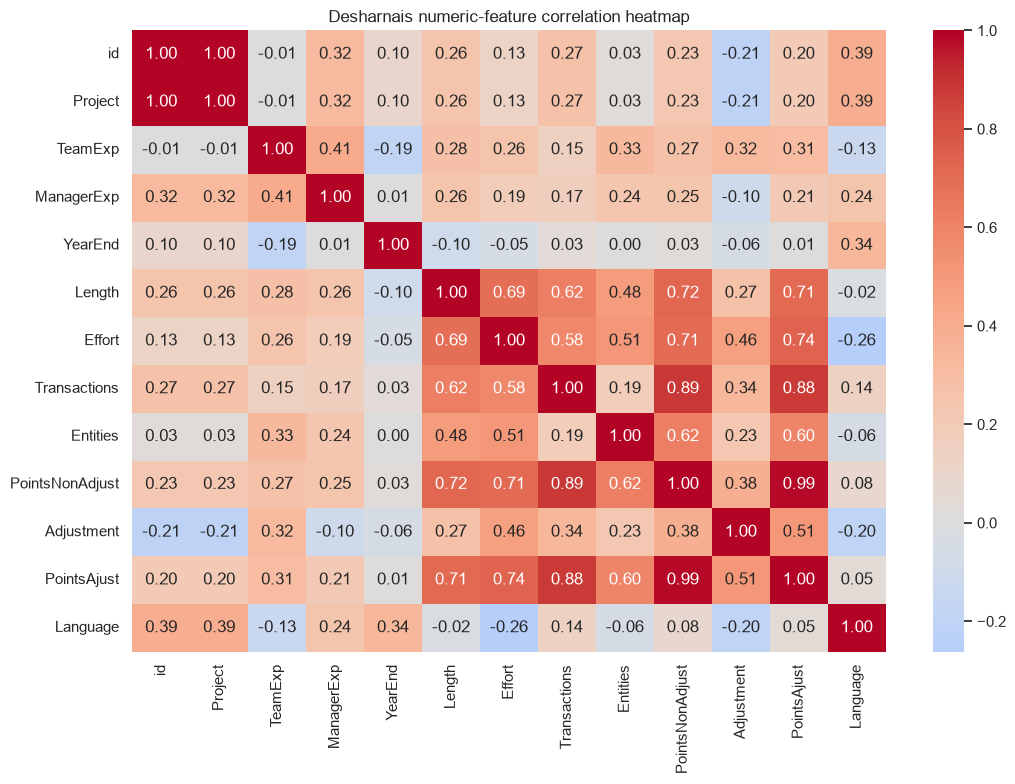

Takeaway: Function-point measures may correlate with effort; inspect correlations carefully because the dataset is small.


In [38]:
numeric_desh = desharnais.select_dtypes(include="number")
plt.figure(figsize=(11, 8))
sns.heatmap(numeric_desh.corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Desharnais numeric-feature correlation heatmap")
plt.tight_layout()
plt.show()
print("Takeaway: Function-point measures may correlate with effort; inspect correlations carefully because the dataset is small.")

## 10. Outlier investigation using the IQR rule
The IQR rule flags values below Q1 − 1.5×IQR or above Q3 + 1.5×IQR. These are *potential* outliers, not automatic errors. We report counts and retain all observations.

In [39]:
def iqr_outlier_report(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (series < lower) | (series > upper)
    return {"Q1": q1, "Q3": q3, "IQR": iqr,
            "lower_bound": lower, "upper_bound": upper,
            "outlier_count": int(mask.sum()),
            "outlier_values": series[mask].tolist()}

display(pd.DataFrame({
    "COCOMO81_actual": iqr_outlier_report(cocomo["actual"]),
    "Desharnais_Effort": iqr_outlier_report(desharnais["Effort"])
}).T)

,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_values
COCOMO81_actual,40.5,438.0,397.5,-555.75,1034.25,9,"[2040.0, 1600.0, 1075.0, 11400.0, 6600.0, 6400..."
Desharnais_Effort,2352.0,5922.0,3570.0,-3003.0,11277.0,8,"[14973, 19894, 14987, 12824, 14434, 11361, 138..."


## 11. Productivity exploration
Productivity can be expressed as a size measure divided by effort, but only when the size and effort definitions are understood. For COCOMO-81, this exploratory ratio uses the source `loc` field divided by actual person-months. It is not a standardized productivity metric.

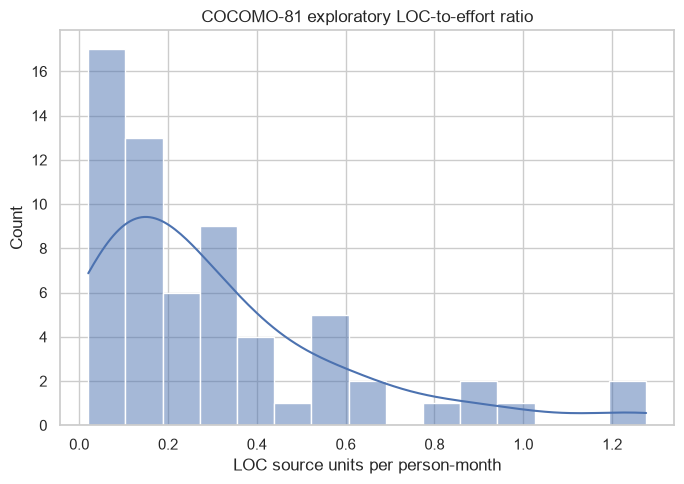

Takeaway: This ratio varies across projects; verify the LOC unit definition before interpreting it as productivity.


In [40]:
cocomo["loc_per_person_month"] = cocomo["loc"] / cocomo["actual"]
plt.figure(figsize=(7, 5))
sns.histplot(cocomo["loc_per_person_month"], bins=15, kde=True)
plt.title("COCOMO-81 exploratory LOC-to-effort ratio")
plt.xlabel("LOC source units per person-month")
plt.tight_layout()
plt.show()
print("Takeaway: This ratio varies across projects; verify the LOC unit definition before interpreting it as productivity.")

## 12. Week 1 findings and limitations
Complete this short reflection after running the notebook:
- Which dataset has the wider relative spread in effort?
- Which fields have missing or sentinel values?
- Which records were flagged as potential outliers, and should they be investigated?
- What relationship did you observe between project size and effort?
- What information about variable definitions or units still needs confirmation?

**Limitations:** Both datasets are small and historically sourced. Their effort units and feature definitions differ. These exploratory plots do not establish causation or model accuracy. No records are removed and no model is trained in Week 1.

## References
- Derek Jones, [Software-estimation-datasets](https://github.com/Derek-Jones/Software-estimation-datasets).
- COCOMO-81 raw CSV: [download](https://raw.githubusercontent.com/Derek-Jones/Software-estimation-datasets/main/COCOMO-81.csv).
- Desharnais raw CSV: [download](https://raw.githubusercontent.com/Derek-Jones/Software-estimation-datasets/main/Desharnais.csv).